# 과제 2 — ACT 정책 학습 및 실로봇 평가

**컴퓨터공학부 · 2021136066 · 손건**  
**실습 장비:** SO-101 Follower, USB 카메라 2대, NVIDIA RTX 4050 Laptop GPU  
**과제 목표:** 과제 1 시연 50개로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가한 뒤 성공률과 학습 결과를 분석한다.

> **작성 기준:** 강의자료 「06. 모방학습 개론 및 실습_v2」의 과제 #2와 제공된 `assignment_2.ipynb` 양식을 기반으로 작성. 실제 사용자 터미널 로그와 보고된 평가 결과만 반영하였다. **Hub의 50K 모델 별도 업로드 및 평가 데이터셋 공개 상태는 아직 검증되지 않았으므로 아래 셀에서 확인한다.**
>
> **실습 환경:** Windows 11 / Python 3.12.16 / LeRobot 0.6.2 / CUDA 지원 PyTorch / W&B. 학습·실물 평가 명령어는 Anaconda Prompt에서 실행하였다. 이 노트북은 **보고서 및 검증용**이므로 실행 자체가 로봇을 움직이지 않는다.

### 진행 결과
- **학습:** 100,000 Steps 완료, W&B 기록 완료, 100K 정책 Hub 업로드 완료.
- **모델 비교:** 100K 정책은 탐색적 테스트에서 물체 접근 실패; **50K 체크포인트는 실제 Pick & Place 성공**.
- **공식 평가:** 50K 정책, 실제 로봇 **10회 성공 / 10회**, **성공률 100%** (사용자 관찰 기록).
- **제출:** GitHub `assignments/assignment_2.ipynb`; **모델 가중치는 GitHub에 업로드 금지**.


## 0. 제출 정보 및 재현 조건

계정과 경로는 실제 실습에 사용한 값을 적었다. Jupyter 커널은 터미널의 `lerobot-act2` 환경과 다를 수 있으므로, **런타임 버전 점검은 정보용**이며 학습 환경 버전은 터미널 로그 기준으로 기록한다.

In [10]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

STUDENT_ID = "2021136066"
NAME = "손건"
DEPARTMENT = "컴퓨터공학부"
HF_USER = "rimur01"
WANDB_ENTITY = "limur01-college-of-engineering"
TASK = "Pick up an object and place it in a target area"
TRAIN_DATASET = f"{HF_USER}/so101-assignment1-50-new"
POLICY_REPO_100K = f"{HF_USER}/act_so101_assignment2"  # 업로드 성공 로그 확인
POLICY_REPO_50K = f"{HF_USER}/act_so101_assignment2_50k"  # 별도 업로드 확인 필요
EVAL_REPO_PREFIX = f"{HF_USER}/rollout_so101_act50k_eval"
# Hub 확인 후 자동 생성된 시각 접미사를 포함한 실제 이름을 아래에 입력
EVAL_DATASET = ""  # 예: rimur01/rollout_so101_act50k_eval_YYYYMMDD_HHMMSS
WANDB_URL = "https://wandb.ai/limur01-college-of-engineering/lerobot/runs/ookbdowg"
LOCAL_POLICY_50K = Path("C:/Users/손건/lerobot/outputs/train/act_so101_assignment2/checkpoints/050000/pretrained_model")

print(f"제출자: {DEPARTMENT} / {STUDENT_ID} / {NAME}")
print("학습 데이터셋:", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("100K 학습 모델:", f"https://huggingface.co/{POLICY_REPO_100K}")
print("50K 평가 모델 (업로드 확인 필요):", f"https://huggingface.co/{POLICY_REPO_50K}")
print("W&B 학습 기록:", WANDB_URL)
print("평가 데이터셋:", EVAL_DATASET or "실제 업로드 주소 확인 필요")
print("Jupyter 커널 Python:", sys.executable)
try:
    print("Jupyter 커널 LeRobot 버전:", version("lerobot"))
except PackageNotFoundError:
    print("Jupyter 커널 LeRobot: 미설치 (노트북 분석에는 무방; 실제 학습 환경은 0.6.2)")


제출자: 컴퓨터공학부 / 2021136066 / 손건
학습 데이터셋: https://huggingface.co/datasets/rimur01/so101-assignment1-50-new
100K 학습 모델: https://huggingface.co/rimur01/act_so101_assignment2
50K 평가 모델 (업로드 확인 필요): https://huggingface.co/rimur01/act_so101_assignment2_50k
W&B 학습 기록: https://wandb.ai/limur01-college-of-engineering/lerobot/runs/ookbdowg
평가 데이터셋: 실제 업로드 주소 확인 필요
Jupyter 커널 Python: C:\Users\손건\AppData\Local\Programs\Python\Python310\python.exe
Jupyter 커널 LeRobot: 미설치 (노트북 분석에는 무방; 실제 학습 환경은 0.6.2)


### 0-1. 학습/평가 장비 및 데이터

| 구분 | 실제 설정 |
|---|---|
| 학습용 Conda 환경 | `C:\lerobot-envs\lerobot-act2` |
| 학습 모델 | ACT (Action Chunking with Transformer) |
| 시연 데이터 | `rimur01/so101-assignment1-50-new`, 50 Episodes / 15,000 Frames |
| 로봇 | SO-101 Follower, `COM6`, ID `my_follower` |
| 카메라 | `cam0` 인덱스 0 / `cam1` 인덱스 1, 640×480, 15 FPS, MJPG, DirectShow |
| 학습 GPU | NVIDIA GeForce RTX 4050 Laptop GPU (VRAM 약 6 GB) |
| W&B | 필수 활성화, 위 학습 Run URL에 기록 |

학습 데이터셋은 과제 1에서 수집한 Pick & Place 시연을 사용하였다. 목표 작업은 물체를 집어 지정한 목표 영역으로 옮긴 다음 놓는 것이다.

### 0-2. Hugging Face Hub 제출 파일 점검

다음 셀은 네트워크가 허용되는 PC에서 **직접 공개 저장소를 조회**한다. 처음에는 `CHECK_HUB=False`로 되어 있어 로컬에서 안전하게 실행되며, 실제 제출 전에 `True`로 바꾸어 다시 실행해야 한다. 조회 실패는 업로드 성공으로 처리하지 않는다.

모델 50K를 별도 업로드할 경우 먼저 아래 명령어를 **터미널**에서 실행한다. 이미 업로드한 경우 재실행하지 않아도 된다.

```bat
cd /d C:\Users\손건\lerobot
python -c "from huggingface_hub import HfApi; a=HfApi(); r='rimur01/act_so101_assignment2_50k'; a.create_repo(repo_id=r,repo_type='model',exist_ok=True); a.upload_folder(repo_id=r,repo_type='model',folder_path='outputs/train/act_so101_assignment2/checkpoints/050000/pretrained_model'); print('업로드 완료:', r)"
```

**중요:** 50K의 `pretrained_model` 폴더 안에 정책 가중치뿐 아니라 정책 전·후처리 관련 파일이 포함되었는지 확인한다. 로컬에서는 해당 체크포인트로 실제 추론이 성공했지만, Hub에서도 별도로 정상 로딩되는지 확인해야 한다.

In [11]:
CHECK_HUB = False  # 제출 전 True로 변경하여 모든 검증 셀을 다시 실행
hub_state = {"train_dataset": None, "policy_100k": None, "policy_50k": None, "eval_dataset": None}
repo_files = {}

if not CHECK_HUB:
    print("[미검증] Hub 확인을 건너뜀. 실제 제출 전에 CHECK_HUB=True로 바꾸어 재실행하세요.")
else:
    from huggingface_hub import HfApi, hf_hub_download
    api = HfApi()
    targets = [("train_dataset", TRAIN_DATASET, "dataset"),
               ("policy_100k", POLICY_REPO_100K, "model"),
               ("policy_50k", POLICY_REPO_50K, "model")]
    if EVAL_DATASET:
        targets.append(("eval_dataset", EVAL_DATASET, "dataset"))
    for key, rid, typ in targets:
        try:
            meta = api.repo_info(repo_id=rid, repo_type=typ)
            files = api.list_repo_files(rid, repo_type=typ)
            repo_files[key] = files
            hub_state[key] = (not meta.private)
            print(("[공개 확인]" if not meta.private else "[비공개]") + f" {rid} (파일 {len(files)}개)")
        except Exception as exc:
            hub_state[key] = False
            print(f"[접근 불가] {rid}: {type(exc).__name__}: {str(exc)[:110]}")
    if not EVAL_DATASET:
        print("[미확인] EVAL_DATASET에 실제 timestamp 포함 저장소 ID를 입력해야 함")


[미검증] Hub 확인을 건너뜀. 실제 제출 전에 CHECK_HUB=True로 바꾸어 재실행하세요.


### 0-3. 평가 데이터셋 실제 저장소 이름 찾기

`lerobot-rollout` 평가에서는 업로드 시 시간 접미사가 추가될 수 있다. 로그/Hub에서 실제 저장소를 확인한 뒤 위 0번 셀의 `EVAL_DATASET`을 채운다. 아래 코드는 **업로드가 완료되었는지** 확인하는 보조 코드다. 저장소가 보이지 않는다고 10회의 실제 성공 기록이 없어지는 것은 아니지만, **영상 업로드 제출 증빙은 별도로 필요**하다.

In [12]:
if not CHECK_HUB:
    print("[미검증] CHECK_HUB=True 설정 후 실행하면 rollout 평가 데이터셋 후보를 검색합니다.")
else:
    try:
        matches = [d.id for d in api.list_datasets(author=HF_USER)
                   if "rollout_so101_act50k_eval" in d.id]
        print("평가 데이터셋 후보:", *(matches or ["검색 결과 없음"]), sep="\n - ")
        if len(matches) == 1 and not EVAL_DATASET:
            print("설정할 값: EVAL_DATASET =", repr(matches[0]))
        if len(matches) > 1:
            print("여러 개가 검색됨. 실제 10회 평가 로그에 대응하는 저장소를 직접 선택하세요.")
    except Exception as exc:
        print("평가 데이터셋 검색 실패:", type(exc).__name__, str(exc)[:160])


[미검증] CHECK_HUB=True 설정 후 실행하면 rollout 평가 데이터셋 후보를 검색합니다.


## 1. ACT 정책 학습

### 1-1. 실제 실행한 학습 명령어

아래 명령은 실제 `lerobot-act2` 환경에서 실행한 **100,000 Steps 본 학습**이다.

```bat
lerobot-train --dataset.repo_id=rimur01/so101-assignment1-50-new --dataset.root=C:/lerobot_data/so101-assignment1-50-new --policy.type=act --policy.device=cuda --policy.repo_id=rimur01/act_so101_assignment2 --policy.push_to_hub=true --output_dir=outputs/train/act_so101_assignment2 --job_name=act_so101_assignment2 --batch_size=1 --steps=100000 --save_freq=10000 --log_freq=200 --seed=1000 --num_workers=0 --wandb.enable=true
```

### 1-2. 학습 설정 및 완료 결과

| 항목 | 실제 값 / 근거 |
|---|---|
| 정책 구조 | ACT / ResNet-18 영상 인코더 / Action Chunking |
| 스텝 수 | **100,000 Steps** (완료 로그 확인) |
| 배치 크기 | **1** (RTX 4050 VRAM을 고려해 강의 예시 8에서 축소) |
| Checkpoint 주기 | **10,000 Steps** |
| 로그 주기 | **200 Steps** |
| Seed | 1000 |
| 학습 장치 | CUDA / RTX 4050 |
| 학습 데이터 | 50 Episodes / 15,000 Frames |
| W&B | `--wandb.enable=true` / 학습 Run 기록 |
| 총 학습 시간 | **4시간 41분 24초** |
| 평균 진행 속도 | **5.92 Steps/s** |
| 최종 모델 업로드 | **성공** — 로그 `Model pushed to https://huggingface.co/rimur01/act_so101_assignment2` |

평가 결과가 가장 좋았던 체크포인트는 100K가 아니라 **50K**이므로, 실제 로봇 평가는 `checkpoints/050000/pretrained_model`을 사용하였다.

In [13]:
# 실제 터미널 기록에 근거한 학습 완료 요약 (임의 생성한 결과가 아님)
training_log = {
    "total_steps": 100000,
    "training_duration": "4:41:24",
    "mean_steps_per_second": 5.92,
    "total_episodes": 50,
    "total_frames": 15000,
    "batch_size": 1,
    "save_freq": 10000,
    "model_100k_push_logged": True,
    "selected_eval_checkpoint": 50000,
}
display(pd.DataFrame([training_log]).T.rename(columns={0: "실측/로그 결과"}))


,실측/로그 결과
total_steps,100000
training_duration,4:41:24
mean_steps_per_second,5.92
total_episodes,50
total_frames,15000
batch_size,1
save_freq,10000
model_100k_push_logged,True
selected_eval_checkpoint,50000


### 1-3. 정책 설정 확인 (Hub `config.json`)

모델 설정값은 Hub에 업로드된 파일에서 읽어와 출력한다. **100K와 50K 모델은 학습 정책 구조가 같고 가중치가 다르다.** `CHECK_HUB=True`로 변경한 뒤 실행하면 된다.

In [14]:
policy_config = None
if not CHECK_HUB:
    print("[미검증] CHECK_HUB=True로 설정하면 Hub의 config.json을 출력합니다.")
else:
    try:
        import json
        path = hf_hub_download(POLICY_REPO_100K, "config.json", repo_type="model")
        with open(path, encoding="utf-8") as f:
            policy_config = json.load(f)
        fields = ["type", "chunk_size", "n_action_steps", "n_obs_steps", "vision_backbone", "dim_model", "use_vae", "kl_weight"]
        display(pd.DataFrame([(k, policy_config.get(k, "미기록")) for k in fields], columns=["설정", "값"]))
    except Exception as exc:
        print("정책 설정 조회 실패:", type(exc).__name__, str(exc)[:140])


[미검증] CHECK_HUB=True로 설정하면 Hub의 config.json을 출력합니다.


### 1-4. 학습 Loss 곡선 (W&B 필수)

전체 100,000 Steps의 원본 학습 Loss는 아래 W&B Run에서 확인한다.

**[W&B ACT 학습 기록 열기](https://wandb.ai/limur01-college-of-engineering/lerobot/runs/ookbdowg)**

- **제출 전:** W&B에서 학습 Loss 그래프를 캡처하여 GitHub 저장소의 `images/loss_curve.png`에 저장하거나, 아래 그래프 조회 셀을 실행해 파일을 생성한다.
- 바로 아래 첫 그래프는 **대화에 실제로 남아 있는 초기 200~4,200 Steps의 로그만** 시각화한 것이다. **100K 전체 손실 곡선을 대체하지 않는다.**

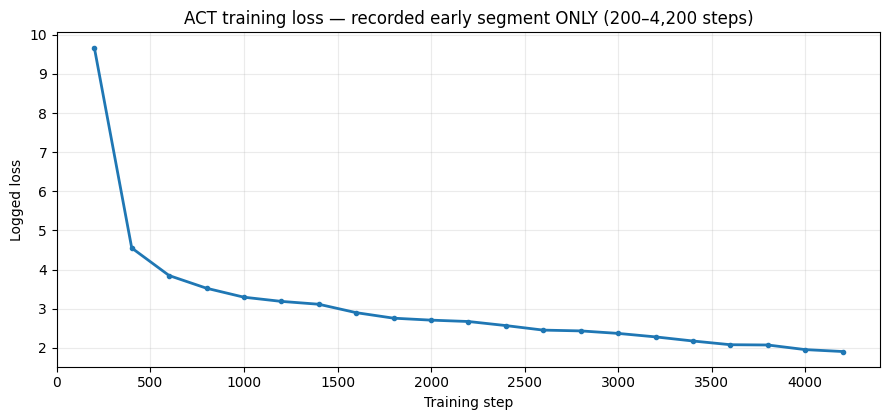

전체 100,000 Steps 곡선은 W&B Run 링크 및 다음 셀에서 확인할 것


In [15]:
# 사용자가 제공한 100K 본 학습의 초반 출력값만 사용한 실제 로그 구간 그래프
observed_loss = [
    (200, 9.673), (400, 4.551), (600, 3.846), (800, 3.522),
    (1000, 3.293), (1200, 3.186), (1400, 3.113), (1600, 2.898),
    (1800, 2.757), (2000, 2.707), (2200, 2.672), (2400, 2.568),
    (2600, 2.452), (2800, 2.432), (3000, 2.368), (3200, 2.279),
    (3400, 2.174), (3600, 2.079), (3800, 2.072), (4000, 1.954), (4200, 1.905),
]
loss_df = pd.DataFrame(observed_loss, columns=["step", "loss"])
plt.figure(figsize=(9, 4.3))
plt.plot(loss_df["step"], loss_df["loss"], linewidth=2, marker="o", markersize=3)
plt.title("ACT training loss — recorded early segment ONLY (200–4,200 steps)")
plt.xlabel("Training step")
plt.ylabel("Logged loss")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("전체 100,000 Steps 곡선은 W&B Run 링크 및 다음 셀에서 확인할 것")


### 1-5. W&B 전체 Loss 그래프 자동 가져오기 (선택)

이미 `wandb login`을 완료한 PC에서 아래 셀의 `FETCH_WANDB=True`로 바꾼 뒤 실행한다. 실제 W&B 기록을 받아 **`images/loss_curve.png`로 저장**한다. 실패할 경우 위 W&B 웹사이트에서 직접 캡처해 같은 파일명으로 저장한다. W&B API 인증 정보는 노트북/깃허브에 넣지 않는다.

In [16]:
FETCH_WANDB = False  # 본인 PC에서 로그인한 후 True로 변경
LOSS_IMAGE = Path("images/loss_curve.png")

if not FETCH_WANDB:
    print("W&B 자동 다운로드 미실행. 제출 전 FETCH_WANDB=True로 실행하거나 직접 캡처를 넣으세요.")
else:
    try:
        import wandb
        run = wandb.Api().run("limur01-college-of-engineering/lerobot/ookbdowg")
        history = run.history(samples=10000, pandas=True)
        # LeRobot / W&B 설정에 따라 손실 지표 이름이 다를 수 있으므로 실제 기록을 탐색한다.
        cols = [c for c in history.columns if "loss" in c.lower()]
        print("W&B에서 찾은 Loss 관련 컬럼:", cols)
        pref = [c for c in ["train/loss", "loss", "train_loss"] if c in cols]
        key = (pref or [c for c in cols if "kld" not in c.lower() and "l1" not in c.lower()] or cols)
        if not key:
            raise ValueError("Loss 지표가 발견되지 않음. 웹페이지에서 지표 이름을 확인하세요.")
        xcol = "_step" if "_step" in history.columns else "_runtime"
        curve = history[[xcol, key[0]]].dropna()
        if curve.empty:
            raise ValueError("Loss 곡선의 유효한 데이터가 없음")
        LOSS_IMAGE.parent.mkdir(parents=True, exist_ok=True)
        plt.figure(figsize=(10, 4.5))
        plt.plot(curve[xcol], curve[key[0]], linewidth=1.5)
        plt.title(f"ACT training loss — W&B ({key[0]})")
        plt.xlabel(xcol); plt.ylabel(key[0]); plt.grid(alpha=0.25)
        plt.tight_layout(); plt.savefig(LOSS_IMAGE, dpi=170)
        plt.show()
        print("W&B 전체 곡선 저장:", LOSS_IMAGE, "데이터 점 수:", len(curve))
    except Exception as exc:
        print("W&B 그래프 가져오기 실패:", type(exc).__name__, str(exc)[:260])
        print("W&B 웹 Run에서 직접 Loss 그래프를 캡처해 images/loss_curve.png로 저장하세요.")


W&B 자동 다운로드 미실행. 제출 전 FETCH_WANDB=True로 실행하거나 직접 캡처를 넣으세요.


## 2. 실제 로봇 평가 (10회)

### 2-1. 체크포인트 비교 및 모델 선정

100K 학습 완료 직후, 업로드한 최종 모델로 `base` 전략의 실제 로봇 테스트를 진행하였다. 로봇이 움직이고 카메라가 정상 연결되는 것은 확인했으나 **물체 근처에도 접근하지 못하여 실패**하였다. 이후 50K 체크포인트를 사용한 20초 테스트에서 **Pick & Place 동작을 성공**하였고, 이를 최종 평가 정책으로 선정하였다.

| 모델 | 평가 구분 | 사용자 관찰 결과 |
|---|---|---|
| 100,000 Steps | 사전 탐색 테스트 (공식 10회 평가 아님) | 물체에 접근하지 못함 (실패) |
| **50,000 Steps** | 사전 20초 테스트 | 물체 집기·목표 위치 놓기 성공 |
| **50,000 Steps** | **공식 실로봇 10회 평가** | **10회 전부 성공 (100%)** |

> 학습 스텝이 많을수록 항상 실로봇 성공률이 높아지는 것은 아니다. 이번 결과만으로 100K의 성능이 통계적으로 열등하다고 결론 내릴 수는 없으나, **실제 평가 조건에서 50K가 더 적합했다**는 것을 확인하였다.

### 2-2. 실제 평가에 사용한 명령어

공식 10회 평가는 아래의 `lerobot-rollout --strategy.type=episodic` 설정을 사용하였다. 카메라 이름은 학습 데이터셋과 동일한 `cam0`, `cam1`이다. `base`는 탐색적 움직임 테스트에만 사용했으며 공식 10회 평가와 구분했다.

```bat
lerobot-rollout --strategy.type=episodic --policy.path=outputs/train/act_so101_assignment2/checkpoints/050000/pretrained_model --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{cam0: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --device=cuda --fps=15 --display_data=false --dataset.repo_id=rimur01/rollout_so101_act50k_eval --dataset.root=C:/lerobot_data/rollout_so101_act50k_eval --dataset.single_task="Pick up an object and place it in a target area" --dataset.fps=15 --dataset.num_episodes=10 --dataset.episode_time_s=20 --dataset.reset_time_s=15 --dataset.push_to_hub=true --return_to_initial_position=false
```

실제 로봇을 안전한 환경에서 시험하고, 동일한 성공 기준을 적용하였다. **위 명령의 Hub 업로드 완료 로그는 제공되지 않았으므로 평가 데이터셋 저장소의 공개 여부 및 에피소드 수는 아래 코드로 별도 검증한다.**

### 2-3. 평가 데이터셋의 메타데이터 검증

제출 전에 `EVAL_DATASET`에 **실제로 올라간 저장소 ID**를 입력하고 `CHECK_HUB=True`로 실행해야 한다. 업로드 상태를 모르면 결과를 `미확인`으로 남긴다.

In [17]:
eval_info = None
if not CHECK_HUB:
    print("[미검증] CHECK_HUB=True로 설정하여 Hub 메타데이터를 확인하세요.")
elif not EVAL_DATASET:
    print("[미확인] EVAL_DATASET에 실제 timestamp를 포함한 repo_id 입력 필요")
else:
    try:
        import json
        p = hf_hub_download(EVAL_DATASET, "meta/info.json", repo_type="dataset")
        with open(p, encoding="utf-8") as f:
            eval_info = json.load(f)
        print("실제 업로드된 에피소드 수:", eval_info.get("total_episodes"))
        print("총 프레임 수:", eval_info.get("total_frames"))
        print("FPS:", eval_info.get("fps"))
        print("영상 키:", [k for k in eval_info.get("features", {}) if k.startswith("observation.images")])
        print("10개 확인:", eval_info.get("total_episodes") == 10)
        print("저장소 URL:", f"https://huggingface.co/datasets/{EVAL_DATASET}")
    except Exception as exc:
        print("평가 데이터셋 확인 실패:", type(exc).__name__, str(exc)[:200])


[미검증] CHECK_HUB=True로 설정하여 Hub 메타데이터를 확인하세요.


### 2-4. 회차별 성공 여부 및 성공률 계산

아래 결과는 **실제 사용자 관찰 기록**이다. 공식 평가 1~10회 모두 성공(O)으로 보고하였으며, 임의로 생성한 모델 예측 결과가 아니다. 에피소드 인덱스는 LeRobot의 기본 0~9를 사용하였다.

In [18]:
results = [
    {"episode": idx, "trial": idx + 1, "success": True, "result": "O", "note": "물체 집기 및 목표 영역 놓기 성공 (사용자 확인)"}
    for idx in range(10)
]
res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
n_failure = len(res_df) - n_success
success_rate = n_success / len(res_df) * 100

display(res_df[["trial", "episode", "result", "note"]].rename(columns={
    "trial": "평가 회차", "episode": "데이터셋 인덱스", "result": "결과", "note": "관찰 내용"}))
print(f"총 {len(res_df)}회 | 성공 {n_success}회 | 실패 {n_failure}회 | 성공률 {success_rate:.1f}%")
assert len(res_df) == 10 and n_success == 10


,평가 회차,데이터셋 인덱스,결과,관찰 내용
0,1,0,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
1,2,1,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
2,3,2,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
3,4,3,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
4,5,4,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
5,6,5,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
6,7,6,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
7,8,7,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
8,9,8,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)
9,10,9,O,물체 집기 및 목표 영역 놓기 성공 (사용자 확인)


총 10회 | 성공 10회 | 실패 0회 | 성공률 100.0%


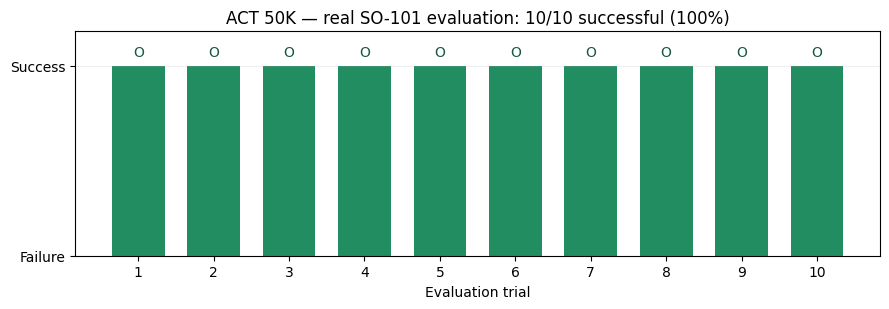

In [19]:
# 공식 평가 결과: 사용자 관찰값을 그래프로 요약
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(res_df["trial"].astype(str), res_df["success"].astype(int), color="#238d62", width=0.7)
ax.set_ylim(0, 1.18)
ax.set_yticks([0, 1], ["Failure", "Success"])
ax.set_xlabel("Evaluation trial")
ax.set_title(f"ACT 50K — real SO-101 evaluation: {n_success}/{len(res_df)} successful ({success_rate:.0f}%)")
ax.grid(axis="y", alpha=0.18)
for i in range(10):
    ax.text(i, 1.035, "O", ha="center", va="bottom", fontsize=10, color="#18593f")
plt.tight_layout()
plt.show()


### 2-5. 평가 영상 및 재현성 확인

평가 데이터셋이 Hub에 업로드되었다면 [LeRobot 데이터셋 뷰어](https://huggingface.co/spaces/lerobot/visualize_dataset)에서 `EVAL_DATASET`의 실제 ID로 재생 여부를 확인한다.

- 사용자 보고 평가: 10회 모두 성공(O), 실패 사례 없음. 따라서 제공된 양식의 **실패 GIF는 해당 없음**이며, 성공 사례 영상 1개 이상만 캡처하는 편이 사실에 부합한다.
- 과제 제출 전에 `images/evaluation_success.png` 같은 대표 성공 장면을 추가할 수 있다. 영상이나 이미지를 올리지 않았다면 임의의 스크린샷을 넣지 않는다.
- **주의:** 100K 정책의 초기 탐색 실패는 공식 50K 평가의 실패 회차에 포함하지 않는다.

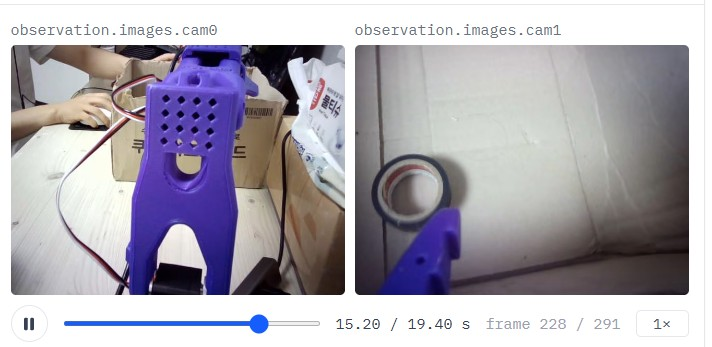

In [25]:
from pathlib import Path
from IPython.display import Image, display

candidate = Path("images/evaluation_success.png")

if candidate.exists():
    display(Image(filename=str(candidate)))
else:
    print("대표 평가 사진 미첨부:", candidate)

## 3. 고찰

### 3-1. 실패 원인 분석

공식 평가에 사용한 **50,000 Steps 모델은 10회 모두 성공했으므로 공식 평가 중 실패 사례는 없었다.** 다만 모델 선택 과정에서 100,000 Steps 정책은 로봇이 움직였음에도 물체에 접근하지 못하는 문제가 있었다. 카메라 연결과 시점, 시작 자세를 확인한 후 50,000 Steps 체크포인트로 변경하자 실제 Pick & Place 작업이 수행되었다. 이는 최종 학습 스텝의 정책이 항상 실로봇에 가장 적합하다고 볼 수 없음을 보여준다. 다만 100K 정책은 소수의 탐색 테스트만 진행했으므로 정확한 실패 원인을 확정하기보다는 체크포인트별 일반화 성능이나 과적합 가능성을 후속 검증 대상으로 보는 것이 적절하다.

### 3-2. 데이터와 성능의 관계

과제 1에서 수집한 **50개 시연 데이터**의 관측 영상과 관절 행동 정보로 ACT 정책을 학습하였다. 50K 정책에서 안정적인 성공 결과가 나타난 것은 시연이 Pick & Place 작업의 주요 이동 경로와 그리퍼 제어 동작을 학습하는 데 도움이 되었기 때문으로 해석할 수 있다. 반면 같은 데이터로 100K까지 학습한 정책이 실제 테스트에서 실패했기 때문에, 손실 감소와 실제 성능은 별도로 평가해야 한다는 점을 확인하였다. 특히 현재 10회 실험은 비슷한 작업 조건에서 이루어진 것으로, 물체 위치를 크게 바꿨을 때의 일반화 성능까지 입증한 것은 아니다.

### 3-3. 개선 아이디어

첫째, 물체 위치와 초기 자세를 조금씩 변화시킨 시연 및 회복 행동 시연을 추가해 분포 이동에 대한 대응 능력을 높일 수 있다. 둘째, 30K·40K·50K·60K·100K 등 여러 체크포인트를 동일한 조건에서 반복 평가하여 가장 안정적인 모델을 선택할 필요가 있다. 셋째, 학습 손실뿐 아니라 별도 검증 데이터나 실제 로봇 평가 결과를 기준으로 조기 종료 시점을 결정하는 방법을 고려할 수 있다. 넷째, 물체 위치·조명·카메라 각도를 바꾼 추가 실험을 수행하여 이번에 얻은 100%의 성공률이 다른 조건에서도 유지되는지 확인하고 싶다.

### 3-4. 실습 소감

이번 실습에서 직접 수집한 시연 데이터로 로봇이 행동을 학습하고, 리더암 없이 자율적으로 물체를 집어 옮기는 모습을 확인할 수 있었다. 처음에는 100,000 Steps까지 학습했기 때문에 더 높은 성능을 기대했지만 실제 테스트에서 실패하여 예상과 달랐다. 이후 중간 체크포인트인 50,000 Steps를 적용하자 작업을 성공적으로 수행했고, 10회 평가에서도 모두 성공하였다. 이를 통해 모델 학습 과정뿐 아니라 실제 환경에서의 반복 평가와 체크포인트 선정이 중요하다는 것을 배웠다.